Dataset Initialized: Found 1800 images.

--- FOLD 1 ---
Early Stopping triggered at epoch 75
Fold 1 Finished. Val Dice: 0.8804

--- FOLD 2 ---
Early Stopping triggered at epoch 59
Fold 2 Finished. Val Dice: 0.8382

--- FOLD 3 ---
Early Stopping triggered at epoch 87
Fold 3 Finished. Val Dice: 0.8589

--- FOLD 4 ---
Early Stopping triggered at epoch 71
Fold 4 Finished. Val Dice: 0.8483

--- FOLD 5 ---
Early Stopping triggered at epoch 46
Fold 5 Finished. Val Dice: 0.8554


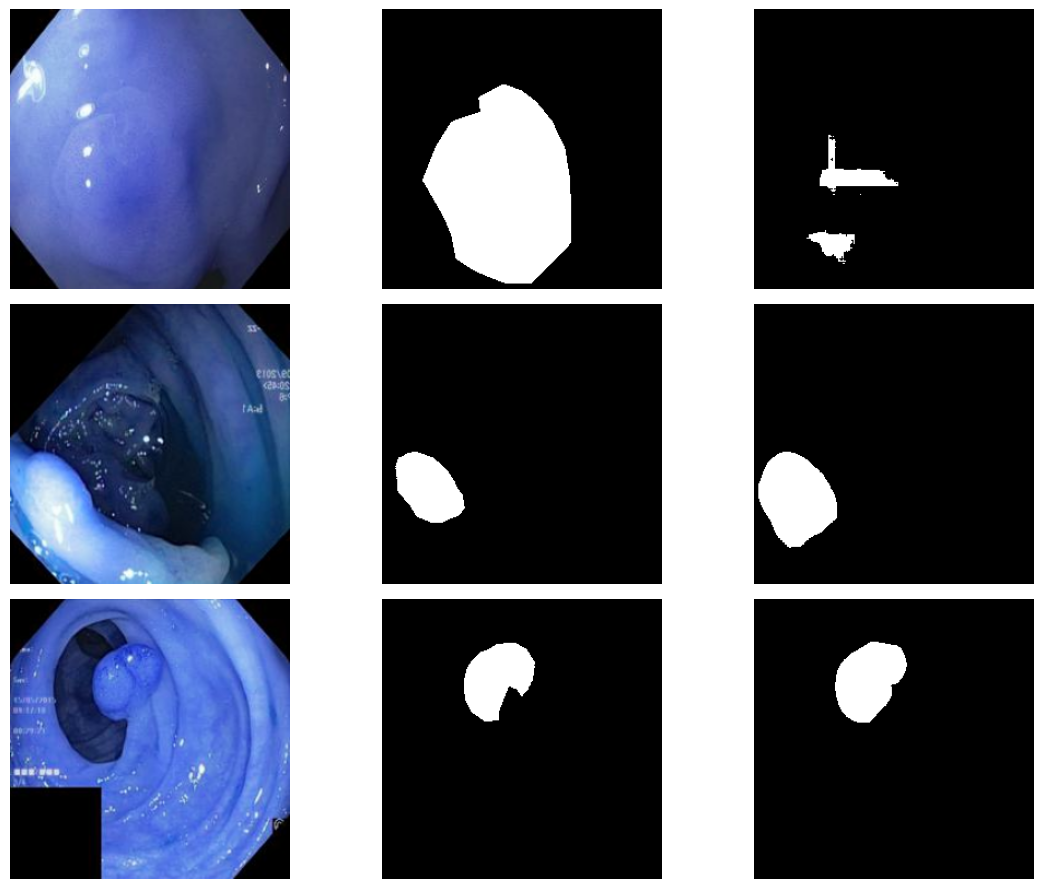


CSV Saved. Process Complete.


In [13]:
import os
import cv2
import numpy as np
from glob import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import precision_score, recall_score, f1_score

# ==========================================
# 1. EARLY STOPPING CLASS
# ==========================================
class EarlyStopping:
    def __init__(self, patience=7, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

# ... [SegmentationDataset, DiceLoss, and UNet classes remain same as previous] ...



def get_metrics(loader, model, device):
    model.eval()
    m_loss, m_acc, m_prec, m_rec, m_f1, m_iou, m_dice = [], [], [], [], [], [], []
    criterion_bce, criterion_dice = nn.BCELoss(), DiceLoss()
    
    with torch.no_grad():
        for imgs, msks in loader:
            imgs, msks = imgs.to(device), msks.to(device)
            outputs = model(imgs)
            loss = criterion_bce(outputs, msks) + criterion_dice(outputs, msks)
            preds = (outputs > 0.5).float()
            
            y_true = msks.cpu().numpy().flatten()
            y_pred = preds.cpu().numpy().flatten()
            
            m_loss.append(loss.item())
            m_acc.append((preds == msks).sum().item() / torch.numel(msks))
            m_prec.append(precision_score(y_true, y_pred, zero_division=0))
            m_rec.append(recall_score(y_true, y_pred, zero_division=0))
            m_f1.append(f1_score(y_true, y_pred, zero_division=0))
            
            inter = (preds * msks).sum().item()
            union = (preds + msks).clamp(0, 1).sum().item()
            m_iou.append((inter + 1e-6) / (union + 1e-6))
            m_dice.append((2 * inter + 1e-6) / (preds.sum().item() + msks.sum().item() + 1e-6))
            
    return np.mean(m_loss), np.mean(m_acc), np.mean(m_prec), np.mean(m_rec), np.mean(m_f1), np.mean(m_iou), np.mean(m_dice)

# ==========================================
# 2. MAIN K-FOLD PROCESS WITH EARLY STOPPING
# ==========================================
def train_with_kfold():
    image_dir = r"D:\Biose\Train\DatasetOG\Dataset\image"
    mask_dir = r"D:\Biose\Train\DatasetOG\Dataset\label"
    batch_size, lr, epochs, k_folds = 4, 1e-4, 100, 5 # Increased max epochs since we have Early Stopping
    device = "cuda" if torch.cuda.is_available() else "cpu"

    dataset = SegmentationDataset(image_dir, mask_dir, augment=True)
    kfold = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    final_csv_data = []

    for fold, (train_ids, val_ids) in enumerate(kfold.split(dataset)):
        print(f"\n--- FOLD {fold + 1} ---")
        train_loader = DataLoader(Subset(dataset, train_ids), batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(Subset(dataset, val_ids), batch_size=1, shuffle=False)
        
        model = UNet().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        criterion_bce, criterion_dice = nn.BCELoss(), DiceLoss()
        
        # Initialize Early Stopping for this fold
        early_stopper = EarlyStopping(patience=10, min_delta=0.001)

        for epoch in range(epochs):
            model.train()
            for imgs, msks in train_loader:
                imgs, msks = imgs.to(device), msks.to(device)
                optimizer.zero_grad()
                out = model(imgs)
                loss = criterion_bce(out, msks) + criterion_dice(out, msks)
                loss.backward(); optimizer.step()

            # Check validation loss for Early Stopping
            v_loss_only, _, _, _, _, _, _ = get_metrics(val_loader, model, device)
            early_stopper(v_loss_only)
            
            if early_stopper.early_stop:
                print(f"Early Stopping triggered at epoch {epoch+1}")
                break

        # Generate Full Metrics for the CSV
        t_metrics = get_metrics(train_loader, model, device)
        v_metrics = get_metrics(val_loader, model, device)
        
        row = {
            'fold': fold + 1,
            'train_loss': t_metrics[0], 'train_accu': t_metrics[1], 'train_prec': t_metrics[2], 
            'train_reca': t_metrics[3], 'train_f1': t_metrics[4], 'train_iou': t_metrics[5], 'train_dice': t_metrics[6],
            'val_loss': v_metrics[0], 'val_accu': v_metrics[1], 'val_prec': v_metrics[2], 
            'val_reca': v_metrics[3], 'val_f1': v_metrics[4], 'val_iou': v_metrics[5], 'val_dice': v_metrics[6]
        }
        final_csv_data.append(row)
        print(f"Fold {fold+1} Finished. Val Dice: {v_metrics[6]:.4f}")

        # Visualization and Saving (Last Fold)
        if fold + 1 == k_folds:
            plt.figure(figsize=(12, 9))
            for i, (img, msk) in enumerate(val_loader):
                if i >= 3: break
                pred = (model(img.to(device)) > 0.5).float().cpu().squeeze().numpy()
                plt.subplot(3, 3, i*3+1); plt.imshow(img[0].permute(1,2,0)); plt.axis('off')
                plt.subplot(3, 3, i*3+2); plt.imshow(msk[0].squeeze(), cmap='gray'); plt.axis('off')
                plt.subplot(3, 3, i*3+3); plt.imshow(pred, cmap='gray'); plt.axis('off')
            plt.tight_layout(); plt.show()
            torch.save(model.state_dict(), "unet_final_model.pth")

    pd.DataFrame(final_csv_data).to_csv("comprehensive_metrics.csv", index=False)
    print("\nCSV Saved. Process Complete.")

train_with_kfold()